# Fourier harmonic sensitivity — how many harmonics does `model_4_ord` need?

The main analysis (`Bayes_GLM_cum_ord_logit_hypoth.ipynb`) fits the cumulative-logit
ordinal model `model_4_ord` with **two** Fourier harmonics on each cycle: the diel
cycle (period 24 h) and the seasonal cycle (period 366 d). Two harmonics per cycle is
a modelling choice, not a result, so this notebook refits the *identical* model with
**K = 2, 3, 4 and 5** harmonics per cycle and asks two separate questions.

**1. Does predictive fit improve?** Models are compared by PSIS-LOO expected
log pointwise predictive density (`elpd_loo`). Because every model is fitted to the
same rows, the comparison uses the **paired** difference of the pointwise elpd,
whose standard error is
$\mathrm{SE}(\Delta) = \sqrt{n}\;\mathrm{sd}(\mathrm{elpd}_i^{A}-\mathrm{elpd}_i^{B})$ —
much smaller than the difference of the two marginal SEs, and the quantity used by
`loo_compare`. A difference is read as real only when $|\Delta\mathrm{elpd}| > 2\,\mathrm{SE}$.
LOO penalises effective complexity through `p_loo`, but maximum-likelihood BIC is reported
alongside every ladder step (Section 11) as an explicitly parameter-counting cross-check.

**2. Are the hypothesis-bearing coefficients stable?** Predictive fit is only half the
question: the harmonics are nuisance terms, and what matters for the paper's hypotheses
is whether temperature, humidity, their quadratics, their interaction and heterospecific
calling keep the same sign, magnitude and credible-interval support as K grows. Stability
is quantified as the shift in posterior mean expressed in reference posterior SDs
($\Delta/\mathrm{SD}$), together with sign and zero-exclusion agreement.

Everything except the number of harmonics — data, rows, priors, link, cut-point priors,
sampler settings and seed — is held fixed, so any change is attributable to K alone.

**Paper items produced here:** Table S4 (`tables/TableS4_fourier_harmonics_hypothesis_ladder.*`) and
Fig. S4 (`figures/FigS4_coefficients_by_harmonics.*`). The K = 2 fits are shared with
`01_main_analysis.ipynb` through the cache in `outputs/`; K = 3–5 add 30 fits (≈ 2–5 min each on a first run).

## 0. Setup & configuration

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import arviz as az
import bambi as bmb
from patsy import dmatrix
from statsmodels.miscmodels.ordinal_model import OrderedModel

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

np.set_printoptions(linewidth=150)
pd.set_option("display.width", 2000)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)


# ══ FIGURE STYLE TOGGLES (mirrors the main notebook) ═════════════════════════
FONT_SCALE = 1.0
LINE_SCALE = 1.0

FS_TITLE      = 20 * FONT_SCALE
FS_SUPTITLE   = 21 * FONT_SCALE
FS_LABEL      = 21 * FONT_SCALE
FS_TICK       = 15 * FONT_SCALE
FS_LEGEND     = 16 * FONT_SCALE

LW_MAIN      = 2.8 * LINE_SCALE
LW_SECONDARY = 2.2 * LINE_SCALE
LW_AUX       = 1.6 * LINE_SCALE
LW_SPINE     = 1.2 * LINE_SCALE
LW_GRID      = 1.0 * LINE_SCALE
CAPSIZE      = 5.0 * LINE_SCALE
# ═════════════════════════════════════════════════════════════════════════════

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": FS_TICK,
    "axes.titlesize": FS_TITLE,
    "axes.labelsize": FS_LABEL,
    "figure.titlesize": FS_SUPTITLE,
    "xtick.labelsize": FS_TICK,
    "ytick.labelsize": FS_TICK,
    "legend.fontsize": FS_LEGEND,
    "figure.figsize": (14, 6),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": LW_GRID,
    "lines.linewidth": LW_MAIN,
    "axes.linewidth": LW_SPINE,
    "xtick.major.width": LW_SPINE,
    "ytick.major.width": LW_SPINE,
    "axes.spines.top": False,
    "axes.spines.right": True,
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman", "STIXGeneral", "DejaVu Serif", "Times New Roman"],
    "mathtext.fontset": "cm",
    # cmr10 has no U+2212 glyph; use the ASCII hyphen so negative
    # tick labels render as -0.10 rather than a missing-glyph box.
    "axes.unicode_minus": False,
})

COLORS = {"gastro": "#1f77b4", "oreo": "#ff7f0e"}

SPECIES = ["Gastrotheca chrysosticta", "Oreobates berdemenos"]
SP_SHORT = {
    "Gastrotheca chrysosticta": "G. chrysosticta",
    "Oreobates berdemenos": "O. berdemenos",
}
SP_COLOR = {
    "Gastrotheca chrysosticta": COLORS["gastro"],
    "Oreobates berdemenos": COLORS["oreo"],
}

import frogcall as fc

PLOT_DIR = fc.FIG_DIR
PAPER_FIGURES = {"coefficient_forest_by_harmonics": "FigS4_coefficients_by_harmonics"}


def savefig(fig, name):
    """Save a figure into figures/ as PDF, under its paper number."""
    fc.save_figure(fig, PAPER_FIGURES[name])


print("Setup complete. Figures will be saved to:", PLOT_DIR.resolve())

Setup complete. Figures will be saved to: /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/figures


## 1. The harmonic grid and the fitting configuration

`HS_VARY` controls which cycle the harmonic count applies to. The default `"both"`
expands the diel and the seasonal basis together, so K = 2 reproduces `model_4_ord`
exactly and each step of K adds four coefficients (a sine/cosine pair per cycle).
Set it to `"diel"` or `"seasonal"` to hold the other cycle at the reference count.

Sampler settings, priors and seed are copied from Section 4 of the main notebook so
that the K = 2 fit already on disk *is* the reference fit and is reused rather than
resampled.

In [2]:
# ── Harmonic grid ────────────────────────────────────────────────────────────
HS_K_VALUES = [2, 3, 4, 5]   # harmonics per cycle to compare
HS_K_REF    = 2              # the count used throughout the main analysis
HS_VARY     = "both"         # "both" | "diel" | "seasonal"

# ── Sampler / prior settings (identical to Section 4 of the main notebook) ───
BAYES_DRAWS         = 1000
BAYES_TUNE          = 1000
BAYES_CHAINS        = 4
BAYES_CORES         = 1
BAYES_TARGET_ACCEPT = 0.9
BAYES_SEED          = 42
HS_PRIORS = {"common": bmb.Prior("Normal", mu=0, sigma=1)}

# ── Caching ──────────────────────────────────────────────────────────────────
# The full log_likelihood group is ~360 MB per model, so it is used to compute the
# pointwise elpd immediately after sampling, persisted as a small .npz (the only
# thing the paired ELPD comparison needs), and then dropped before caching the
# posterior. Set HS_SAVE_LOGLIK = True to keep the heavyweight group instead.
HS_MODEL_DIR = fc.MODEL_DIR
HS_TABLE_DIR = fc.TABLE_DIR / "supporting"
HS_ELPD_DIR  = fc.ELPD_DIR
for _d in (HS_MODEL_DIR, HS_TABLE_DIR, HS_ELPD_DIR):
    _d.mkdir(parents=True, exist_ok=True)

HS_REFIT       = False   # True → resample even when a cached posterior exists
HS_SAVE_LOGLIK = False   # True → keep log_likelihood inside the cached .nc

HS_MODEL = "model_4_ord"


def hs_k_pair(K: int) -> Tuple[int, int]:
    """(diel harmonics, seasonal harmonics) for grid point K."""
    if HS_VARY == "both":
        return K, K
    if HS_VARY == "diel":
        return K, HS_K_REF
    if HS_VARY == "seasonal":
        return HS_K_REF, K
    raise ValueError(f"HS_VARY must be 'both', 'diel' or 'seasonal', got {HS_VARY!r}")


def hs_label(K: int, latex: bool = False) -> str:
    kd, ks = hs_k_pair(K)
    return rf"$K={K}$" if latex else f"K={K}"


def hs_nc_path(sp: str, K: int) -> Path:
    return HS_MODEL_DIR / f"{HS_MODEL}_K{K}{HS_VARY[0]}_{sp.replace(' ', '_')}.nc"


def hs_legacy_nc_path(sp: str, K: int) -> Optional[Path]:
    """The Section-4 cache is itself the K = 2 fit — same formula, data, seed."""
    if K == HS_K_REF and HS_VARY == "both":
        return HS_MODEL_DIR / f"{HS_MODEL}_{sp.replace(' ', '_')}.nc"
    return None


def hs_elpd_path(sp: str, K: int) -> Path:
    return HS_ELPD_DIR / f"elpd_pointwise_K{K}{HS_VARY[0]}_{sp.replace(' ', '_')}.npz"


# Distinct colour / marker per K, used consistently in every figure below.
HS_K_COLOR  = dict(zip(HS_K_VALUES, ["#1b4965", "#2a9d8f", "#e9c46a", "#e76f51",
                                     "#9b5de5", "#457b9d"]))
HS_K_MARKER = dict(zip(HS_K_VALUES, ["o", "s", "D", "^", "v", "P"]))

print(f"Comparing K = {HS_K_VALUES} (varying: {HS_VARY}); reference K = {HS_K_REF}")
for _K in HS_K_VALUES:
    _kd, _ks = hs_k_pair(_K)
    print(f"  K={_K}: {_kd} diel + {_ks} seasonal harmonics → {2 * (_kd + _ks)} harmonic coefficients")

Comparing K = [2, 3, 4, 5] (varying: both); reference K = 2
  K=2: 2 diel + 2 seasonal harmonics → 8 harmonic coefficients
  K=3: 3 diel + 3 seasonal harmonics → 12 harmonic coefficients
  K=4: 4 diel + 4 seasonal harmonics → 16 harmonic coefficients
  K=5: 5 diel + 5 seasonal harmonics → 20 harmonic coefficients


## 2. Data

The row filter is copied verbatim from the main notebook — including the columns that
`model_4_ord` never uses (`other_calling_bin`, `other_calling_lag1`, whose lag drops the
first timestamp). This matters: a paired ELPD comparison is only valid if every model is
fitted to exactly the same observations in the same order, and reusing the cached K = 2
posterior additionally requires those rows to match the ones it was fitted to.

All harmonics up to `max(HS_K_VALUES)` are built once, so the design matrices for
different K are nested columns of a single data frame and no re-filtering is possible.

In [3]:
DATA_PATH = fc.DATA_PATH

TEMP_COL = "Temp"
RH_COL   = "RH%"

df = pd.read_csv(DATA_PATH)
df["DateTime"] = pd.to_datetime(df["DateTime"], errors="coerce")
df = df.set_index("DateTime").sort_index()

print(f"Raw shape: {df.shape}")
print(f"Date range: {df.index.min()} → {df.index.max()}")

K_MAX = max(HS_K_VALUES)


def zscore(series: pd.Series) -> pd.Series:
    return (series - series.mean()) / series.std(ddof=0)


def add_fourier_terms(d: pd.DataFrame, k_diel: int, k_seas: int) -> pd.DataFrame:
    """sin/cos pairs for harmonics 1..k of the 24 h and 366 d cycles."""
    two_pi = 2 * np.pi
    for j in range(1, k_diel + 1):
        d[f"sin_h{j}"] = np.sin(j * two_pi * d["hour"] / 24.0)
        d[f"cos_h{j}"] = np.cos(j * two_pi * d["hour"] / 24.0)
    for j in range(1, k_seas + 1):
        d[f"sin_d{j}"] = np.sin(j * two_pi * d["doy"] / 366.0)
        d[f"cos_d{j}"] = np.cos(j * two_pi * d["doy"] / 366.0)
    return d


def prepare_species_df(df_in: pd.DataFrame, response_col: str) -> pd.DataFrame:
    df_local = df_in.copy()
    df_local["temp_z"] = zscore(pd.to_numeric(df_local[TEMP_COL], errors="coerce"))
    df_local["rh_z"]   = zscore(pd.to_numeric(df_local[RH_COL],   errors="coerce"))

    df_local["hour"] = df_local.index.hour
    df_local["doy"]  = df_local.index.dayofyear
    df_local = add_fourier_terms(df_local, K_MAX, K_MAX)

    other_col = [c for c in SPECIES if c != response_col][0]
    df_local["other_calling_ord"]  = pd.to_numeric(df_local[other_col], errors="coerce")
    df_local["other_calling_bin"]  = (df_local["other_calling_ord"] > 0).astype(int)
    df_local["other_calling_lag1"] = df_local["other_calling_bin"].shift(1)
    df_local["response_raw"]       = pd.to_numeric(df_local[response_col], errors="coerce")

    harmonic_cols = ([f"sin_h{j}" for j in range(1, K_MAX + 1)]
                     + [f"cos_h{j}" for j in range(1, K_MAX + 1)]
                     + [f"sin_d{j}" for j in range(1, K_MAX + 1)]
                     + [f"cos_d{j}" for j in range(1, K_MAX + 1)])
    model_cols = [
        "response_raw", "temp_z", "rh_z",
        "other_calling_ord", "other_calling_bin", "other_calling_lag1",
        "hour", "doy",
    ] + harmonic_cols
    df_model = df_local[model_cols].dropna()

    response_cat = pd.Categorical(df_model["response_raw"], ordered=True)
    df_model["response_code"] = response_cat.codes
    df_model["response_cat"]  = response_cat
    return df_model


species_data = {sp: prepare_species_df(df, sp) for sp in SPECIES}

HS_N_OBS = {sp: int(d.shape[0]) for sp, d in species_data.items()}
print("\nRows per species (must match the cached model_4_ord fits):", HS_N_OBS)
for sp, d in species_data.items():
    counts = d["response_raw"].value_counts().sort_index()
    print(f"  {SP_SHORT[sp]:<17} categories: {dict(counts)}")

Raw shape: (13257, 8)
Date range: 2018-09-02 00:00:00 → 2020-07-18 23:00:00

Rows per species (must match the cached model_4_ord fits): {'Gastrotheca chrysosticta': 11302, 'Oreobates berdemenos': 11302}
  G. chrysosticta   categories: {0: np.int64(10287), 1: np.int64(378), 2: np.int64(384), 3: np.int64(253)}
  O. berdemenos     categories: {0: np.int64(10533), 1: np.int64(305), 2: np.int64(377), 3: np.int64(87)}


## 3. Model formulas

`model_4_ord` is the model carried forward for interpretation in the main notebook:
the harmonic basis plus temperature, humidity, both quadratics, their interaction and
the ordinal heterospecific-calling term. Only the harmonic block changes with K.

In [4]:
HS_FIXED_TERMS = [
    "temp_z", "rh_z",
    "I(temp_z ** 2)", "I(rh_z ** 2)",
    "temp_z:rh_z",
    "other_calling_ord",
]


def hs_fourier_terms(K: int) -> List[str]:
    kd, ks = hs_k_pair(K)
    diel = [t for j in range(1, kd + 1) for t in (f"sin_h{j}", f"cos_h{j}")]
    seas = [t for j in range(1, ks + 1) for t in (f"sin_d{j}", f"cos_d{j}")]
    return diel + seas


def hs_terms(K: int) -> List[str]:
    return hs_fourier_terms(K) + HS_FIXED_TERMS


def hs_formula(K: int, response: str = "response_cat") -> str:
    return f"{response} ~ " + " + ".join(hs_terms(K))


# Guard: at the reference K this must be byte-identical to the formula the main
# notebook builds for model_4_ord, otherwise the cached posterior is not reusable.
_EXPECTED_REF_FORMULA = (
    "response_code ~ sin_h1 + cos_h1 + sin_h2 + cos_h2 + sin_d1 + cos_d1 + sin_d2 + cos_d2 "
    "+ temp_z + rh_z + I(temp_z ** 2) + I(rh_z ** 2) + temp_z:rh_z + other_calling_ord"
)
if HS_VARY == "both" and HS_K_REF == 2:
    assert hs_formula(2, "response_code") == _EXPECTED_REF_FORMULA, (
        "Reference formula drifted from the main notebook:\n"
        f"  built:    {hs_formula(2, 'response_code')}\n"
        f"  expected: {_EXPECTED_REF_FORMULA}"
    )
    print("✓ K=2 formula matches model_4_ord in the main notebook\n")

for _K in HS_K_VALUES:
    print(f"K={_K}  ({len(hs_terms(_K))} coefficients + 3 cut-points)")
    print(f"   {hs_formula(_K)}\n")

✓ K=2 formula matches model_4_ord in the main notebook

K=2  (14 coefficients + 3 cut-points)
   response_cat ~ sin_h1 + cos_h1 + sin_h2 + cos_h2 + sin_d1 + cos_d1 + sin_d2 + cos_d2 + temp_z + rh_z + I(temp_z ** 2) + I(rh_z ** 2) + temp_z:rh_z + other_calling_ord

K=3  (18 coefficients + 3 cut-points)
   response_cat ~ sin_h1 + cos_h1 + sin_h2 + cos_h2 + sin_h3 + cos_h3 + sin_d1 + cos_d1 + sin_d2 + cos_d2 + sin_d3 + cos_d3 + temp_z + rh_z + I(temp_z ** 2) + I(rh_z ** 2) + temp_z:rh_z + other_calling_ord

K=4  (22 coefficients + 3 cut-points)
   response_cat ~ sin_h1 + cos_h1 + sin_h2 + cos_h2 + sin_h3 + cos_h3 + sin_h4 + cos_h4 + sin_d1 + cos_d1 + sin_d2 + cos_d2 + sin_d3 + cos_d3 + sin_d4 + cos_d4 + temp_z + rh_z + I(temp_z ** 2) + I(rh_z ** 2) + temp_z:rh_z + other_calling_ord

K=5  (26 coefficients + 3 cut-points)
   response_cat ~ sin_h1 + cos_h1 + sin_h2 + cos_h2 + sin_h3 + cos_h3 + sin_h4 + cos_h4 + sin_h5 + cos_h5 + sin_d1 + cos_d1 + sin_d2 + cos_d2 + sin_d3 + cos_d3 + sin_d4 + 

## 5. Bayesian refits

One `bambi` cumulative-logit fit per species × K. Sampling settings, priors and the
random seed are those of the main analysis, so the K = 2 posterior already on disk is
loaded rather than resampled. Immediately after sampling, the pointwise `elpd_i` is
computed and cached as a small `.npz`; the ~360 MB `log_likelihood` group is then
dropped before the posterior is written to disk.

In [6]:
def hs_build_model(sp: str, K: int) -> bmb.Model:
    return bmb.Model(
        formula=hs_formula(K), data=species_data[sp],
        family="cumulative", priors=HS_PRIORS,
    )


def hs_fit(sp: str, formula: str, label: str):
    """Fit or load one model (shared cache, see frogcall.fit_cached).

    Returns (idata, pointwise elpd, loo stats, sampling seconds).
    """
    fit = fc.fit_cached(formula, species_data[sp], sp, label)
    return fit["idata"], fit["elpd_i"], fit["loo"], fit["seconds"]


hs_idata   = {}   # (species, K) → InferenceData
hs_models  = {}   # (species, K) → bambi.Model
hs_elpd_i  = {}   # (species, K) → pointwise elpd (n_obs,)
hs_loo_st  = {}   # (species, K) → {elpd_loo, loo_se, p_loo, n_pareto_bad}
hs_fit_sec = {}   # (species, K) → sampling time in seconds (nan when loaded)

for sp in SPECIES:
    for K in HS_K_VALUES:
        key = (sp, K)
        hs_models[key] = hs_build_model(sp, K)
        idata, elpd_i, st, secs = hs_fit(sp, hs_formula(K), f"{HS_MODEL}_K{K}")
        hs_idata[key], hs_loo_st[key], hs_fit_sec[key] = idata, st, secs
        hs_elpd_i[key] = elpd_i

print("\nPosteriors available for:", ", ".join(f"{SP_SHORT[s]}/K={k}" for s, k in hs_idata))

# Paired comparisons are only valid on identical observations, so this is enforced.
for sp in SPECIES:
    ns = {k: len(v) for k, v in hs_elpd_i.items() if k[0] == sp}
    assert set(ns.values()) == {HS_N_OBS[sp]}, f"{sp}: {ns}"
print("✓ every model is scored on the same", HS_N_OBS[SPECIES[0]], "observations")

G. chrysosticta   model_4_ord_K2   N(0, 1)  loaded from cache (model_4_ord_K2_sd1_Gastrotheca_chrysosticta_8dc8321c)
G. chrysosticta   model_4_ord_K3   N(0, 1)  loaded from cache (model_4_ord_K3_sd1_Gastrotheca_chrysosticta_1dbb8a4e)


G. chrysosticta   model_4_ord_K4   N(0, 1)  loaded from cache (model_4_ord_K4_sd1_Gastrotheca_chrysosticta_31122ae2)
G. chrysosticta   model_4_ord_K5   N(0, 1)  loaded from cache (model_4_ord_K5_sd1_Gastrotheca_chrysosticta_8f069624)


O. berdemenos     model_4_ord_K2   N(0, 1)  loaded from cache (model_4_ord_K2_sd1_Oreobates_berdemenos_8dc8321c)
O. berdemenos     model_4_ord_K3   N(0, 1)  loaded from cache (model_4_ord_K3_sd1_Oreobates_berdemenos_1dbb8a4e)


O. berdemenos     model_4_ord_K4   N(0, 1)  loaded from cache (model_4_ord_K4_sd1_Oreobates_berdemenos_31122ae2)
O. berdemenos     model_4_ord_K5   N(0, 1)  loaded from cache (model_4_ord_K5_sd1_Oreobates_berdemenos_8f069624)

Posteriors available for: G. chrysosticta/K=2, G. chrysosticta/K=3, G. chrysosticta/K=4, G. chrysosticta/K=5, O. berdemenos/K=2, O. berdemenos/K=3, O. berdemenos/K=4, O. berdemenos/K=5
✓ every model is scored on the same 11302 observations


## 6. Predictive fit: PSIS-LOO elpd and its paired differences

In [7]:
def hs_flat_draws(idata) -> Dict[str, np.ndarray]:
    """{term: 1-D draws} for every posterior variable; vector-valued ones expand to term[i]."""
    out = {}
    for v in idata.posterior.data_vars:
        da = idata.posterior[v]
        extra = [d for d in da.dims if d not in ("chain", "draw")]
        if not extra:
            out[str(v)] = np.asarray(da.values).ravel()
        else:
            for i in range(da.sizes[extra[0]]):
                out[f"{v}[{i}]"] = np.asarray(da.isel({extra[0]: i}).values).ravel()
    return out


def hs_diagnostics(idata) -> pd.DataFrame:
    try:
        diag = az.summary(idata, kind="diagnostics")
    except Exception:
        diag = az.summary(idata)
    return diag.apply(pd.to_numeric, errors="coerce")


_metric_rows = []
for sp in SPECIES:
    for K in HS_K_VALUES:
        idata = hs_idata[(sp, K)]
        diag  = hs_diagnostics(idata)
        div   = (int(idata.sample_stats["diverging"].sum())
                 if "sample_stats" in idata.children and "diverging" in idata.sample_stats
                 else np.nan)
        kd, ks = hs_k_pair(K)
        _metric_rows.append({
            "species": sp, "species_short": SP_SHORT[sp], "K": K,
            "k_diel": kd, "k_seas": ks,
            "n_coef": len(hs_terms(K)), "n_obs": HS_N_OBS[sp],
            **hs_loo_st[(sp, K)],
            "divergences": div,
            "max_r_hat":    float(diag["r_hat"].max())    if "r_hat"    in diag else np.nan,
            "min_ess_bulk": float(diag["ess_bulk"].min()) if "ess_bulk" in diag else np.nan,
            "min_ess_tail": float(diag["ess_tail"].min()) if "ess_tail" in diag else np.nan,
            "sampling_min": hs_fit_sec[(sp, K)] / 60 if np.isfinite(hs_fit_sec[(sp, K)]) else np.nan,
        })

hs_metrics = pd.DataFrame(_metric_rows)
hs_metrics.to_csv(HS_TABLE_DIR / "fourier_harmonics_loo_metrics.csv", index=False)
display(hs_metrics[[
    "species_short", "K", "n_coef", "elpd_loo", "loo_se", "p_loo",
    "n_pareto_bad", "divergences", "max_r_hat", "min_ess_bulk", "min_ess_tail",
]].round(3))

,species_short,K,n_coef,elpd_loo,loo_se,p_loo,n_pareto_bad,divergences,max_r_hat,min_ess_bulk,min_ess_tail
0,G. chrysosticta,2,14,-2539.057,68.388,15.531,0.0,0,1.00,2483.0,2509.0
1,G. chrysosticta,3,18,-2514.372,67.490,18.194,0.0,0,1.00,2318.0,2500.0
2,G. chrysosticta,4,22,-2484.672,67.156,21.168,0.0,0,1.00,2419.0,2559.0
3,G. chrysosticta,5,26,-2480.632,67.107,23.986,0.0,0,1.00,2692.0,2518.0
4,O. berdemenos,2,14,-2224.281,61.065,13.718,0.0,0,1.00,1494.0,1815.0
5,O. berdemenos,3,18,-2189.143,60.216,16.383,6.0,0,1.01,1374.0,1792.0
6,O. berdemenos,4,22,-2155.632,59.282,18.652,12.0,0,1.00,1761.0,2124.0
7,O. berdemenos,5,26,-2130.214,58.990,21.149,7.0,0,1.00,2060.0,2329.0


In [8]:
# ── Paired elpd differences ──────────────────────────────────────────────────
# The models share their observations, so the difference is taken pointwise and its SE is
# sqrt(n) * sd(elpd_i^A - elpd_i^B) — the same quantity `loo_compare` reports. The
# marginal SEs of the two elpd totals are an order of magnitude larger and would hide any
# real difference, which is exactly why the paired form is used.
HS_DECISIVE_SE = 2.0   # |Δelpd| must exceed this many paired SEs to count as a difference


def hs_pair_diff(sp: str, K_a: int, K_b: int) -> Dict[str, float]:
    """elpd(K_a) − elpd(K_b): positive favours K_a (the more complex model by convention)."""
    if (sp, K_a) not in hs_elpd_i or (sp, K_b) not in hs_elpd_i:
        return {"elpd_diff": np.nan, "se_diff": np.nan, "diff_over_se": np.nan}
    d = hs_elpd_i[(sp, K_a)] - hs_elpd_i[(sp, K_b)]
    diff = float(d.sum())
    se   = float(np.sqrt(d.size) * d.std(ddof=1))
    return {"elpd_diff": diff, "se_diff": se,
            "diff_over_se": diff / se if se > 0 else np.nan}


def hs_verdict(diff: float, se: float, name_a: str, name_b: str) -> str:
    if not np.isfinite(diff) or not np.isfinite(se) or se == 0:
        return "unresolved"
    if diff > HS_DECISIVE_SE * se:
        return f"{name_a} better"
    if diff < -HS_DECISIVE_SE * se:
        return f"{name_b} better"
    return "indistinguishable"


_pair_rows = []
for sp in SPECIES:
    for i, K_b in enumerate(HS_K_VALUES):
        for K_a in HS_K_VALUES[i + 1:]:
            r = hs_pair_diff(sp, K_a, K_b)
            _pair_rows.append({
                "species": sp, "species_short": SP_SHORT[sp],
                "K_a": K_a, "K_b": K_b,
                "comparison": f"K={K_a} − K={K_b}",
                "d_coef": len(hs_terms(K_a)) - len(hs_terms(K_b)),
                **r,
                "verdict": hs_verdict(r["elpd_diff"], r["se_diff"], f"K={K_a}", f"K={K_b}"),
            })

hs_pairwise = pd.DataFrame(_pair_rows)
hs_pairwise.to_csv(HS_TABLE_DIR / "fourier_harmonics_elpd_pairwise.csv", index=False)

print("All pairwise comparisons (positive Δelpd favours the more complex model):")
display(hs_pairwise[["species_short", "comparison", "d_coef",
                     "elpd_diff", "se_diff", "diff_over_se", "verdict"]].round(2))

print(f"\nAgainst the reference K={HS_K_REF}:")
display(hs_pairwise.query("K_b == @HS_K_REF")[
    ["species_short", "comparison", "elpd_diff", "se_diff", "diff_over_se", "verdict"]
].round(2))

print("\nSequential (each K against the next-smaller K):")
display(hs_pairwise.query("K_a == K_b + 1")[
    ["species_short", "comparison", "elpd_diff", "se_diff", "diff_over_se", "verdict"]
].round(2))

All pairwise comparisons (positive Δelpd favours the more complex model):


,species_short,comparison,d_coef,elpd_diff,se_diff,diff_over_se,verdict
0,G. chrysosticta,K=3 − K=2,4,24.69,7.63,3.24,K=3 better
1,G. chrysosticta,K=4 − K=2,8,54.39,9.58,5.68,K=4 better
2,G. chrysosticta,K=5 − K=2,12,58.43,11.17,5.23,K=5 better
3,G. chrysosticta,K=4 − K=3,4,29.70,6.38,4.66,K=4 better
4,G. chrysosticta,K=5 − K=3,8,33.74,8.18,4.13,K=5 better
5,G. chrysosticta,K=5 − K=4,4,4.04,3.63,1.11,indistinguishable
6,O. berdemenos,K=3 − K=2,4,35.14,6.29,5.59,K=3 better
7,O. berdemenos,K=4 − K=2,8,68.65,9.26,7.41,K=4 better
8,O. berdemenos,K=5 − K=2,12,94.07,12.02,7.82,K=5 better
9,O. berdemenos,K=4 − K=3,4,33.51,5.88,5.70,K=4 better



Against the reference K=2:


,species_short,comparison,elpd_diff,se_diff,diff_over_se,verdict
0,G. chrysosticta,K=3 − K=2,24.69,7.63,3.24,K=3 better
1,G. chrysosticta,K=4 − K=2,54.39,9.58,5.68,K=4 better
2,G. chrysosticta,K=5 − K=2,58.43,11.17,5.23,K=5 better
6,O. berdemenos,K=3 − K=2,35.14,6.29,5.59,K=3 better
7,O. berdemenos,K=4 − K=2,68.65,9.26,7.41,K=4 better
8,O. berdemenos,K=5 − K=2,94.07,12.02,7.82,K=5 better



Sequential (each K against the next-smaller K):


,species_short,comparison,elpd_diff,se_diff,diff_over_se,verdict
0,G. chrysosticta,K=3 − K=2,24.69,7.63,3.24,K=3 better
3,G. chrysosticta,K=4 − K=3,29.70,6.38,4.66,K=4 better
5,G. chrysosticta,K=5 − K=4,4.04,3.63,1.11,indistinguishable
6,O. berdemenos,K=3 − K=2,35.14,6.29,5.59,K=3 better
9,O. berdemenos,K=4 − K=3,33.51,5.88,5.70,K=4 better
11,O. berdemenos,K=5 − K=4,25.42,6.49,3.92,K=5 better


## 7. Parameter stability

The harmonics are nuisance terms; the paper's hypotheses rest on the environmental and
heterospecific-calling coefficients. For every term of the reference model the posterior
is compared across K on three axes:

* **$\Delta$/SD** — the shift in posterior mean relative to the *reference* posterior SD.
  Below 0.1 the shift is negligible next to the uncertainty already reported.
* **HDI width ratio** and **HDI overlap** — whether the interval changes width or position.
* **Inference stability** — whether the sign of the mean and the 95 % HDI's
  exclusion/inclusion of zero are unchanged. This is the criterion that decides whether a
  conclusion in the paper would read differently.

In [9]:
HS_HDI_PROB = 0.95


def hs_hdi(x, prob: float = HS_HDI_PROB) -> Tuple[float, float]:
    """Highest-density interval of a 1-D sample (independent of the ArviZ version)."""
    x = np.sort(np.asarray(x, dtype=float).ravel())
    n = x.size
    k = max(int(np.floor(prob * n)), 1)
    if k >= n:
        return float(x[0]), float(x[-1])
    widths = x[k:] - x[: n - k]
    i = int(np.argmin(widths))
    return float(x[i]), float(x[i + k])


def hs_summarize(idata, species: str, K: int) -> pd.DataFrame:
    diag = hs_diagnostics(idata)
    rows = []
    for term, draws in hs_flat_draws(idata).items():
        lo, hi = hs_hdi(draws)
        rows.append({
            "species": species, "K": K, "term": term,
            "mean":   float(draws.mean()),
            "sd":     float(draws.std(ddof=1)),
            "median": float(np.median(draws)),
            "hdi_lower": lo, "hdi_upper": hi, "hdi_width": hi - lo,
            "OR":           float(np.exp(draws.mean())),
            "OR_hdi_lower": float(np.exp(lo)),
            "OR_hdi_upper": float(np.exp(hi)),
            "p_gt0": float((draws > 0).mean()),
            "excludes_zero": bool(lo > 0 or hi < 0),
            "r_hat":    float(diag["r_hat"].get(term, np.nan))    if "r_hat"    in diag else np.nan,
            "ess_bulk": float(diag["ess_bulk"].get(term, np.nan)) if "ess_bulk" in diag else np.nan,
        })
    return pd.DataFrame(rows)


hs_summaries = pd.concat(
    [hs_summarize(hs_idata[(sp, K)], sp, K) for sp in SPECIES for K in HS_K_VALUES],
    ignore_index=True,
)

# ── Term labels, grouping and display order ─────────────────────────────────
HS_GROUP_ORDER = ["Environmental", "Heterospecific calling",
                  "Diel harmonics", "Seasonal harmonics", "Cut-points"]

HS_TERM_META = {
    "temp_z":         ("Environmental", "Temperature (z)", r"Temperature ($z$)",  r"Temperature ($z$)"),
    "I(temp_z ** 2)": ("Environmental", "Temperature²",    r"Temperature$^{2}$", r"Temperature$^{2}$"),
    "rh_z":           ("Environmental", "Humidity (z)",    r"Humidity ($z$)",     r"Humidity ($z$)"),
    "I(rh_z ** 2)":   ("Environmental", "Humidity²",       r"Humidity$^{2}$",    r"Humidity$^{2}$"),
    "temp_z:rh_z":    ("Environmental", "Temperature × Humidity",
                       r"Temperature $\times$ Humidity", r"Temperature $\times$ Humidity"),
    "other_calling_ord": ("Heterospecific calling", "Heterospecific calling (ordinal)",
                          r"Heterospecific calling (ordinal)", "Heterospecific calling (ord.)"),
}
for _j in range(1, 12):
    HS_TERM_META[f"sin_h{_j}"] = ("Diel harmonics", f"Diel sin({_j})",
                                  rf"Diel $\sin({_j})$", rf"Diel $\sin({_j})$")
    HS_TERM_META[f"cos_h{_j}"] = ("Diel harmonics", f"Diel cos({_j})",
                                  rf"Diel $\cos({_j})$", rf"Diel $\cos({_j})$")
    HS_TERM_META[f"sin_d{_j}"] = ("Seasonal harmonics", f"Seasonal sin({_j})",
                                  rf"Seasonal $\sin({_j})$", rf"Seasonal $\sin({_j})$")
    HS_TERM_META[f"cos_d{_j}"] = ("Seasonal harmonics", f"Seasonal cos({_j})",
                                  rf"Seasonal $\cos({_j})$", rf"Seasonal $\cos({_j})$")


def _hs_threshold_meta(sp: str) -> Dict[str, tuple]:
    """Cut-point labels named after the category boundary each one separates."""
    cats = list(pd.Categorical(species_data[sp]["response_raw"], ordered=True).categories)
    meta = {}
    for i in range(len(cats) - 1):
        a, b = cats[i], cats[i + 1]
        a = int(a) if float(a).is_integer() else a
        b = int(b) if float(b).is_integer() else b
        meta[f"threshold[{i}]"] = (
            "Cut-points", f"τ{i + 1} ({a} | {b})",
            rf"$\tau_{{{i + 1}}}$ ({a}\,$\vert$\,{b})",
            rf"$\tau_{{{i + 1}}}$ ({a}/{b})",
        )
    return meta


def hs_term_meta(sp: str, term: str) -> tuple:
    """(group, display label, LaTeX label, matplotlib label) for one term."""
    return {**HS_TERM_META, **_hs_threshold_meta(sp)}.get(
        term, ("Other", term, term.replace("_", r"\_"), term.replace("_", " "))
    )


def hs_term_order(sp: str, K: int) -> List[str]:
    """Reference display order: harmonics, environment, heterospecific, cut-points."""
    return hs_terms(K) + [f"threshold[{i}]" for i in range(3)]


_meta = hs_summaries.apply(lambda r: hs_term_meta(r["species"], r["term"]),
                           axis=1, result_type="expand")
hs_summaries[["group", "label", "label_tex", "label_mpl"]] = _meta
hs_summaries.to_csv(HS_TABLE_DIR / "fourier_harmonics_posterior_summaries.csv", index=False)

print(f"{len(hs_summaries)} posterior summaries "
      f"({len(SPECIES)} species × {len(HS_K_VALUES)} harmonic counts)")
display(hs_summaries.query("K == @HS_K_REF and term in @HS_FIXED_TERMS")[
    ["species", "K", "label", "mean", "sd", "hdi_lower", "hdi_upper", "p_gt0", "excludes_zero"]
].round(3))

184 posterior summaries (2 species × 4 harmonic counts)


,species,K,label,mean,sd,hdi_lower,hdi_upper,p_gt0,excludes_zero
11,Gastrotheca chrysosticta,2,Temperature (z),0.865,0.093,0.678,1.043,1.000,True
12,Gastrotheca chrysosticta,2,Humidity (z),2.000,0.115,1.786,2.234,1.000,True
13,Gastrotheca chrysosticta,2,Temperature²,-0.781,0.067,-0.903,-0.637,0.000,True
14,Gastrotheca chrysosticta,2,Humidity²,0.250,0.065,0.120,0.372,1.000,True
15,Gastrotheca chrysosticta,2,Temperature × Humidity,-0.361,0.096,-0.534,-0.159,0.000,True
16,Gastrotheca chrysosticta,2,Heterospecific calling (ordinal),-0.058,0.082,-0.211,0.114,0.241,False
103,Oreobates berdemenos,2,Temperature (z),1.840,0.178,1.505,2.199,1.000,True
104,Oreobates berdemenos,2,Humidity (z),1.724,0.172,1.395,2.068,1.000,True
105,Oreobates berdemenos,2,Temperature²,-1.102,0.142,-1.381,-0.827,0.000,True
106,Oreobates berdemenos,2,Humidity²,-0.373,0.128,-0.620,-0.129,0.001,True


### Fig. S4 — posterior means and 95 % HDIs at each harmonic count

  saved figures/FigS4_coefficients_by_harmonics.pdf


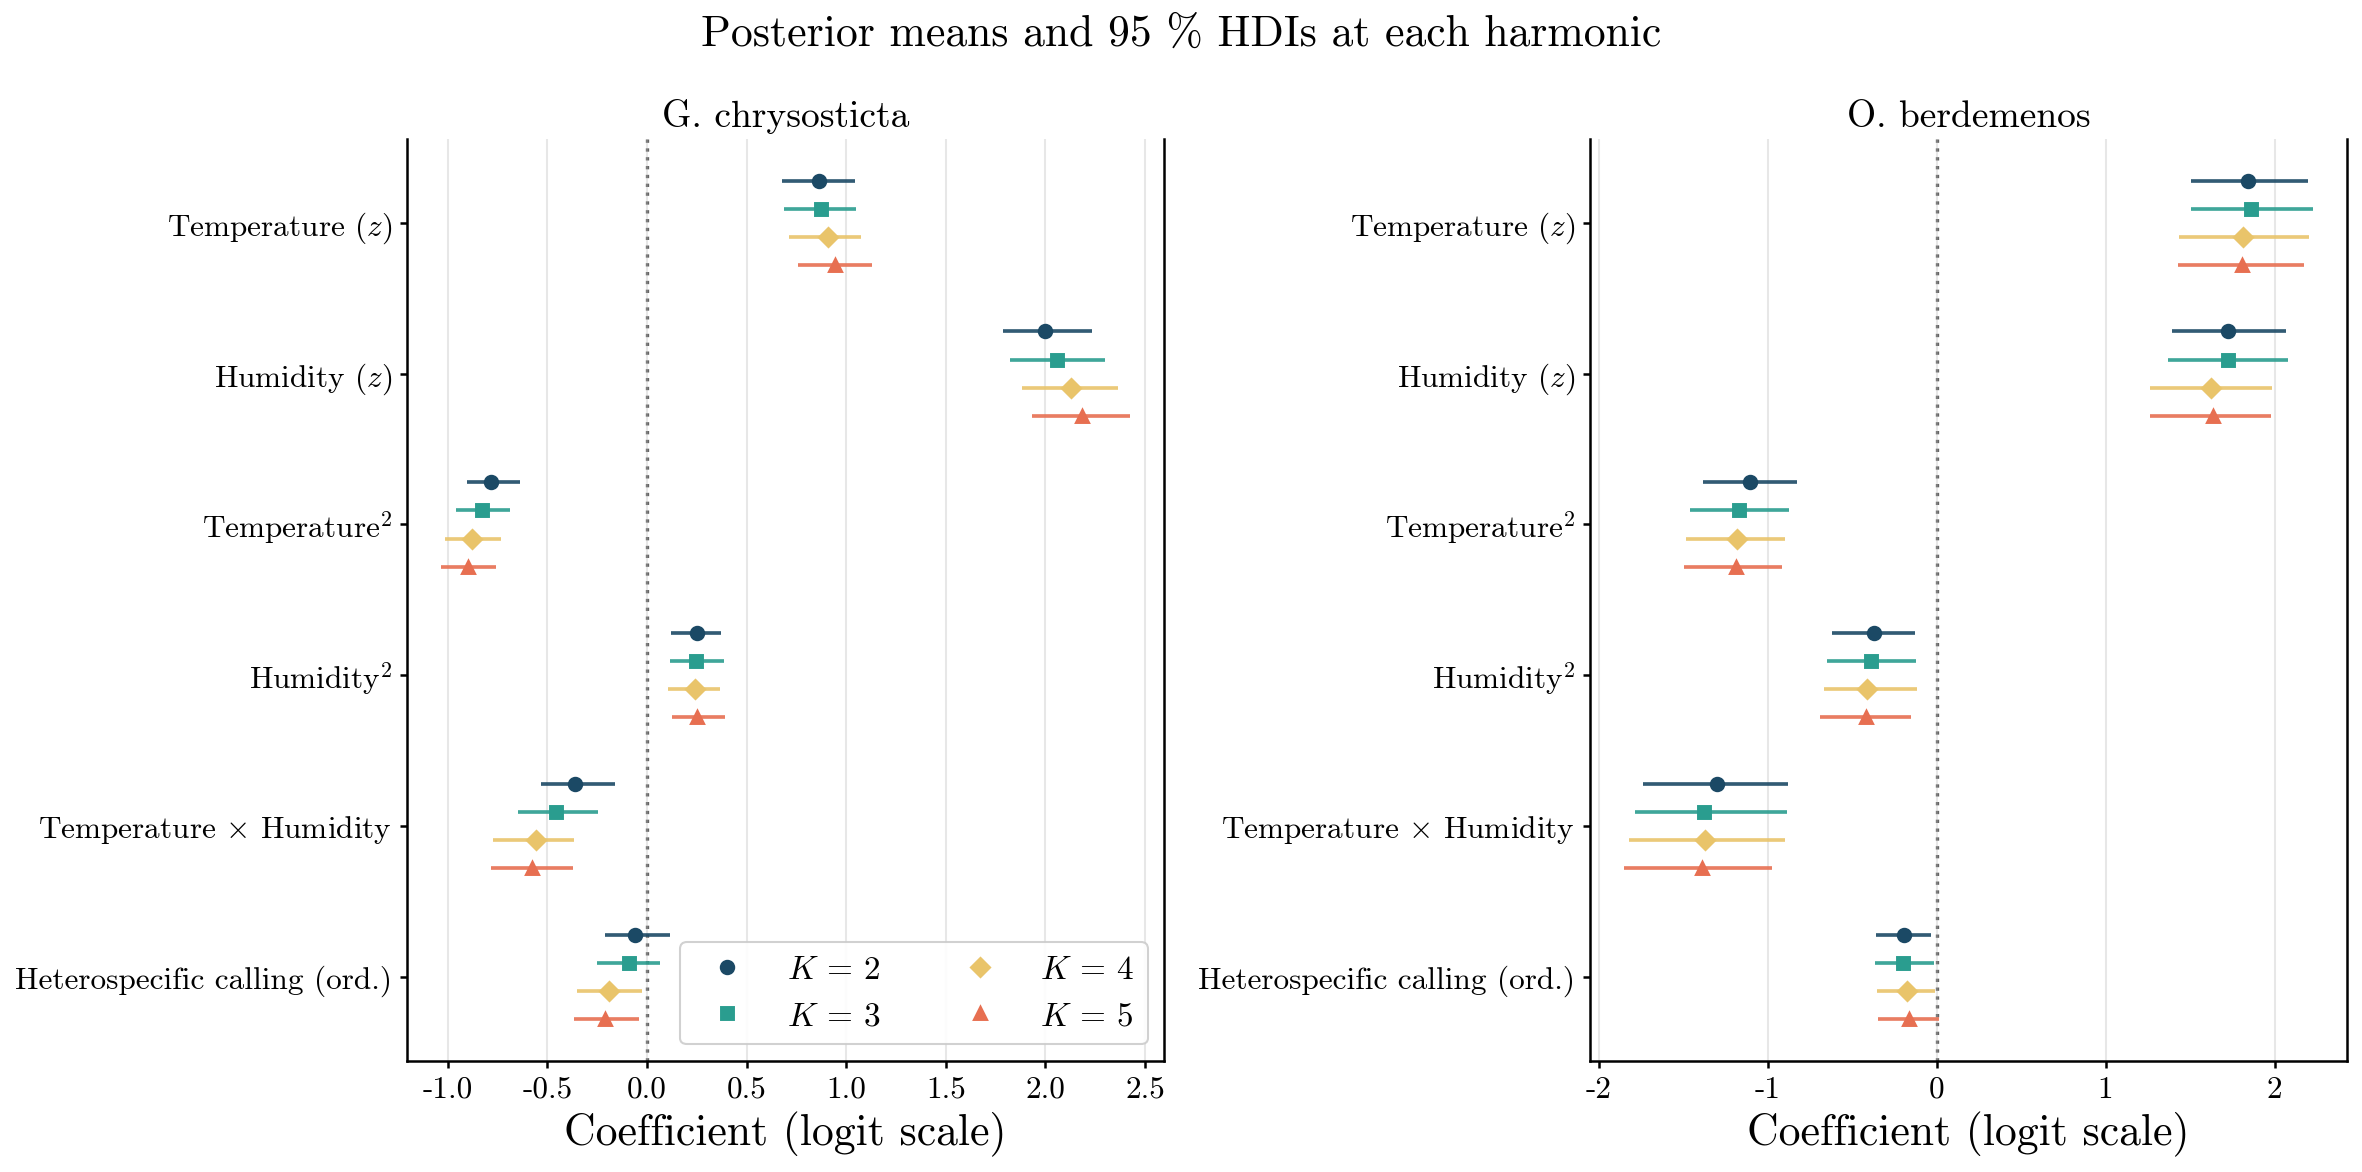

In [10]:
# ── Figure: forest plot of the inference coefficients at each K ──────────────
# Full display order (harmonics + environment + heterospecific + cut-points) is
# still needed downstream; the forest itself keeps only the inference terms.
_forest_terms = hs_term_order(SPECIES[0], HS_K_REF)
_forest_terms_shown = [t for t in _forest_terms if t in HS_FIXED_TERMS]
_offsets = np.linspace(0.28, -0.28, len(HS_K_VALUES))

fig, axes = plt.subplots(1, len(SPECIES),
                         figsize=(8.0 * len(SPECIES), 1.0 * len(_forest_terms_shown) + 2.0))
axes = np.atleast_1d(axes)

for ai, (ax, sp) in enumerate(zip(axes, SPECIES)):
    sub_ref = (hs_summaries.query("species == @sp and K == @HS_K_REF")
               .set_index("term").reindex(_forest_terms_shown).reset_index())
    ypos = np.arange(len(sub_ref))[::-1]

    ax.axvline(0, color="k", lw=LW_AUX, ls=":", alpha=0.6, zorder=1)
    for off, K in zip(_offsets, HS_K_VALUES):
        s = (hs_summaries.query("species == @sp and K == @K")
             .set_index("term").reindex(_forest_terms_shown).reset_index())
        y = ypos + off
        ax.hlines(y, s["hdi_lower"], s["hdi_upper"], color=HS_K_COLOR[K],
                  lw=LW_SECONDARY * 0.8, alpha=0.9, zorder=2)
        ax.plot(s["mean"], y, HS_K_MARKER[K], ms=6, mew=1.4, ls="none", zorder=3,
                color=HS_K_COLOR[K], markeredgecolor=HS_K_COLOR[K],
                label=f"$K$ = {K}")

    ax.set_yticks(ypos)
    ax.set_yticklabels(sub_ref["label_mpl"], fontsize=FS_TICK)
    ax.set_xlabel("Coefficient (logit scale)", fontsize=FS_LABEL)
    ax.set_title(SP_SHORT[sp], fontsize=FS_TITLE * 0.9, style="italic")
    ax.grid(axis="y", visible=False)
    if ai == 0:   # one legend for the whole figure, on the leftmost panel
        ax.legend(fontsize=FS_LEGEND, loc="lower right", framealpha=0.9, ncol=2)

fig.suptitle("Posterior means and 95 % HDIs at each harmonic", fontsize=FS_SUPTITLE)
fig.tight_layout()
savefig(fig, "coefficient_forest_by_harmonics")
plt.show()

## 11. The model ladder at every harmonic count

Sections 5–10 hold the model structure fixed and vary K. This section crosses the two:
the pre-specified nested ladder from the main notebook is refitted at **every** harmonic
count, so each hypothesis test can be read off at K = 2, 3, 4 and 5.

| Rung | Added block | Hypothesis tested against the rung below |
|---|---|---|
| `model_0` | harmonics only | — (temporal baseline) |
| `model_1` | `temp_z`, `rh_z` | H0: weather predicts calling at all |
| `model_2` | `temp_z²`, `rh_z²` | **H1**: the weather effects are non-linear |
| `model_3` | `temp_z:rh_z` | **H2**: temperature and humidity interact |
| `model_4_ord` | `other_calling_ord` | **H3**: heterospecific calling adds information |

Each rung nests the one below it, so every step is a paired comparison on the same
observations: Δelpd with SE(Δ) = √n · sd of the pointwise differences, and a step counts
as real only when |Δelpd| > 2 SE(Δ) — the rule used in the main notebook. Two caveats are
worth keeping in view. First, for *nested* models whose true difference is near zero this
paired SE is known to be optimistic (Sivula, Magnusson & Vehtari 2020), which is why ΔBIC
is reported next to every step. Second, the ladder is pre-specified, so no selection
correction is needed — but the same step is now being read at four harmonic counts, and
the interesting question is whether its verdict is the same at all of them.

`model_4_ord` at each K is reused from Section 5, and `model_2` / `model_3` at K = 2 are
read from the caches the main notebook wrote, so only the genuinely new rungs are sampled.

In [12]:
# ── The ladder ───────────────────────────────────────────────────────────────
# Each entry adds a block of terms to the rung above it; the terms accumulate, so the
# ladder is nested by construction.
HS_BLOCKS = [
    ("model_0",     "Temporal only",            "—",  []),
    ("model_1",     "+ weather",                "H0", ["temp_z", "rh_z"]),
    ("model_2",     "+ non-linear weather",     "H1", ["I(temp_z ** 2)", "I(rh_z ** 2)"]),
    ("model_3",     "+ weather interaction",    "H2", ["temp_z:rh_z"]),
    ("model_4_ord", "+ heterospecific calling", "H3", ["other_calling_ord"]),
]

# The main notebook also defines model_4_bin and model_4_lag1 as alternative encodings of
# the heterospecific term. model_4_ord is the one carried forward for interpretation, so the
# ladder uses it; adding "bin" and/or "lag1" here fits those alternatives as well
# (each variant costs len(HS_K_VALUES) × len(SPECIES) further MCMC runs).
HS_M4_EXTRA = []          # e.g. ["bin", "lag1"]

HS_LADDER  = [b[0] for b in HS_BLOCKS]
HS_LM_NAME = {b[0]: b[1] for b in HS_BLOCKS}
HS_LM_HYP  = {b[0]: b[2] for b in HS_BLOCKS}
for _v in HS_M4_EXTRA:
    HS_LM_NAME[f"model_4_{_v}"] = f"+ heterospecific calling ({_v})"
    HS_LM_HYP[f"model_4_{_v}"]  = "H3"

HS_M4_VARIANT_TERM = {"ord": "other_calling_ord", "bin": "other_calling_bin",
                      "lag1": "other_calling_lag1"}


def hs_ladder_terms(model: str, K: int) -> List[str]:
    """Terms of one rung: the K-harmonic basis plus every block up to and including `model`."""
    if model.startswith("model_4_") and model != "model_4_ord":
        variant = model.rsplit("_", 1)[1]
        return (hs_ladder_terms("model_3", K) + [HS_M4_VARIANT_TERM[variant]])
    terms = list(hs_fourier_terms(K))
    for name, _, _, block in HS_BLOCKS:
        terms += block
        if name == model:
            return terms
    raise KeyError(f"unknown rung {model!r}")


def hs_ladder_formula(model: str, K: int, response: str = "response_cat") -> str:
    return f"{response} ~ " + " + ".join(hs_ladder_terms(model, K))


def hs_lm_models() -> List[str]:
    return HS_LADDER + [f"model_4_{v}" for v in HS_M4_EXTRA]


def hs_lm_nc_path(sp: str, model: str, K: int) -> Path:
    """model_4_ord shares Section 5's cache — same formula, data, priors and seed."""
    if model == "model_4_ord":
        return hs_nc_path(sp, K)
    return HS_MODEL_DIR / f"{model}_K{K}{HS_VARY[0]}_{sp.replace(' ', '_')}.nc"


def hs_lm_elpd_path(sp: str, model: str, K: int) -> Path:
    if model == "model_4_ord":
        return hs_elpd_path(sp, K)
    return HS_ELPD_DIR / f"elpd_pointwise_{model}_K{K}{HS_VARY[0]}_{sp.replace(' ', '_')}.npz"


def hs_lm_legacy_path(sp: str, model: str, K: int) -> Optional[Path]:
    """At the reference K the main notebook's own caches are these very fits."""
    if K == HS_K_REF and HS_VARY == "both":
        p = HS_MODEL_DIR / f"{model}_{sp.replace(' ', '_')}.nc"
        return p if p.exists() else None
    return None


# Guard: the top rung must reproduce Section 5's model exactly, or its cache is not reusable.
for _K in HS_K_VALUES:
    assert hs_ladder_terms("model_4_ord", _K) == hs_terms(_K), (
        f"ladder top rung differs from the Section-5 model at K={_K}")
print("✓ top rung matches the Section-5 model at every K\n")

for _m in hs_lm_models():
    print(f"{_m:<13} {HS_LM_NAME[_m]:<28} "
          f"{len(hs_ladder_terms(_m, HS_K_REF))} coefficients at K={HS_K_REF}")
print(f"\n{len(hs_lm_models())} rungs × {len(HS_K_VALUES)} harmonic counts × "
      f"{len(SPECIES)} species = {len(hs_lm_models()) * len(HS_K_VALUES) * len(SPECIES)} fits")

✓ top rung matches the Section-5 model at every K

model_0       Temporal only                8 coefficients at K=2
model_1       + weather                    10 coefficients at K=2
model_2       + non-linear weather         12 coefficients at K=2
model_3       + weather interaction        13 coefficients at K=2
model_4_ord   + heterospecific calling     14 coefficients at K=2

5 rungs × 4 harmonic counts × 2 species = 40 fits


In [13]:
def fit_ordinal_terms(terms: List[str], df_fit: pd.DataFrame):
    """Maximum-likelihood cumulative-logit fit of an explicit term list."""
    X = dmatrix("0 + " + " + ".join(terms), df_fit, return_type="dataframe")
    y = df_fit["response_code"].astype(int)
    return OrderedModel(endog=y, exog=X, distr="logit").fit(method="bfgs", disp=False)


# ── Frequentist ladder: BIC at every rung × harmonic count ──────────────────
# Cheap next to MCMC and reported alongside every Δelpd, because BIC's explicit log n
# penalty is the stricter test when a step adds parameters.
_lad_freq = []
for sp, df_sp in species_data.items():
    for K in HS_K_VALUES:
        for m in hs_lm_models():
            res = fit_ordinal_terms(hs_ladder_terms(m, K), df_sp)
            k_par = len(res.params)
            _lad_freq.append({
                "species": sp, "species_short": SP_SHORT[sp], "model": m, "K": K,
                "n_coef": len(hs_ladder_terms(m, K)), "n_par": k_par,
                "loglik": float(res.llf),
                "aic": float(-2 * res.llf + 2 * k_par),
                "bic": float(-2 * res.llf + k_par * np.log(res.nobs)),
            })

ladder_freq = pd.DataFrame(_lad_freq)
ladder_freq.to_csv(HS_TABLE_DIR / "fourier_harmonics_ladder_freq_ic.csv", index=False)
print("Maximum-likelihood BIC of every rung (lower is better):")
display(ladder_freq.pivot_table(index=["species_short", "model"], columns="K",
                                values="bic").round(1))

Maximum-likelihood BIC of every rung (lower is better):


K                                 2       3       4       5
species_short   model                                      
G. chrysosticta model_0      6115.4  6128.0  6140.7  6144.4
                model_1      5362.1  5357.2  5357.0  5385.5
                model_2      5161.9  5147.4  5137.9  5163.2
                model_3      5165.2  5141.9  5127.2  5152.7
                model_4_ord  5172.8  5147.0  5128.6  5153.4
O. berdemenos   model_0      4533.8  4546.0  4554.8  4557.8
                model_1      4449.1  4462.2  4462.0  4463.9
                model_2      4436.1  4450.1  4447.8  4450.5
                model_3      4407.7  4420.4  4416.9  4419.0
                model_4_ord  4416.8  4428.7  4426.0  4427.7

In [14]:
# ── Fit or load every rung at every harmonic count ──────────────────────────
ladder_idata   = {}   # (species, model, K) → InferenceData
ladder_elpd_i  = {}
ladder_loo_st  = {}
ladder_fit_sec = {}

for sp in SPECIES:
    for K in HS_K_VALUES:
        for m in hs_lm_models():
            key = (sp, m, K)
            idata, elpd_i, st, secs = hs_fit(sp, hs_ladder_formula(m, K), f"{m}_K{K}")
            ladder_idata[key], ladder_loo_st[key], ladder_fit_sec[key] = idata, st, secs
            if elpd_i is not None:
                ladder_elpd_i[key] = elpd_i

# Paired differences are only valid on identical observations.
_lens = {k: len(v) for k, v in ladder_elpd_i.items()}
for sp in SPECIES:
    ns = {k: n for k, n in _lens.items() if k[0] == sp}
    assert set(ns.values()) == {HS_N_OBS[sp]}, (
        f"{sp}: rungs cover {set(ns.values())} observations, expected {HS_N_OBS[sp]}")
print(f"\n✓ all {len(ladder_elpd_i)} fits scored on the same "
      f"{HS_N_OBS[SPECIES[0]]} observations per species")

G. chrysosticta   model_0_K2       N(0, 1)  loaded from cache (model_0_K2_sd1_Gastrotheca_chrysosticta_dccf9189)
G. chrysosticta   model_1_K2       N(0, 1)  loaded from cache (model_1_K2_sd1_Gastrotheca_chrysosticta_3c482c75)
G. chrysosticta   model_2_K2       N(0, 1)  loaded from cache (model_2_K2_sd1_Gastrotheca_chrysosticta_824e968f)


G. chrysosticta   model_3_K2       N(0, 1)  loaded from cache (model_3_K2_sd1_Gastrotheca_chrysosticta_a04808a9)
G. chrysosticta   model_4_ord_K2   N(0, 1)  loaded from cache (model_4_ord_K2_sd1_Gastrotheca_chrysosticta_8dc8321c)
G. chrysosticta   model_0_K3       N(0, 1)  loaded from cache (model_0_K3_sd1_Gastrotheca_chrysosticta_90bfaa55)


G. chrysosticta   model_1_K3       N(0, 1)  loaded from cache (model_1_K3_sd1_Gastrotheca_chrysosticta_1f67d77a)
G. chrysosticta   model_2_K3       N(0, 1)  loaded from cache (model_2_K3_sd1_Gastrotheca_chrysosticta_06d36216)
G. chrysosticta   model_3_K3       N(0, 1)  loaded from cache (model_3_K3_sd1_Gastrotheca_chrysosticta_6c033292)


G. chrysosticta   model_4_ord_K3   N(0, 1)  loaded from cache (model_4_ord_K3_sd1_Gastrotheca_chrysosticta_1dbb8a4e)
G. chrysosticta   model_0_K4       N(0, 1)  loaded from cache (model_0_K4_sd1_Gastrotheca_chrysosticta_23947279)
G. chrysosticta   model_1_K4       N(0, 1)  loaded from cache (model_1_K4_sd1_Gastrotheca_chrysosticta_d357b355)


G. chrysosticta   model_2_K4       N(0, 1)  loaded from cache (model_2_K4_sd1_Gastrotheca_chrysosticta_df4f7e80)
G. chrysosticta   model_3_K4       N(0, 1)  loaded from cache (model_3_K4_sd1_Gastrotheca_chrysosticta_f1bd6d01)
G. chrysosticta   model_4_ord_K4   N(0, 1)  loaded from cache (model_4_ord_K4_sd1_Gastrotheca_chrysosticta_31122ae2)


G. chrysosticta   model_0_K5       N(0, 1)  loaded from cache (model_0_K5_sd1_Gastrotheca_chrysosticta_cd310ebf)
G. chrysosticta   model_1_K5       N(0, 1)  loaded from cache (model_1_K5_sd1_Gastrotheca_chrysosticta_1debd79c)


... (5 outputs left out)

O. berdemenos     model_1_K4       N(0, 1)  loaded from cache (model_1_K4_sd1_Oreobates_berdemenos_d357b355)
O. berdemenos     model_2_K4       N(0, 1)  loaded from cache (model_2_K4_sd1_Oreobates_berdemenos_df4f7e80)
O. berdemenos     model_3_K4       N(0, 1)  loaded from cache (model_3_K4_sd1_Oreobates_berdemenos_f1bd6d01)


O. berdemenos     model_4_ord_K4   N(0, 1)  loaded from cache (model_4_ord_K4_sd1_Oreobates_berdemenos_31122ae2)
O. berdemenos     model_0_K5       N(0, 1)  loaded from cache (model_0_K5_sd1_Oreobates_berdemenos_cd310ebf)
O. berdemenos     model_1_K5       N(0, 1)  loaded from cache (model_1_K5_sd1_Oreobates_berdemenos_1debd79c)


O. berdemenos     model_2_K5       N(0, 1)  loaded from cache (model_2_K5_sd1_Oreobates_berdemenos_27951d14)
O. berdemenos     model_3_K5       N(0, 1)  loaded from cache (model_3_K5_sd1_Oreobates_berdemenos_f6e2652e)


O. berdemenos     model_4_ord_K5   N(0, 1)  loaded from cache (model_4_ord_K5_sd1_Oreobates_berdemenos_8f069624)

✓ all 40 fits scored on the same 11302 observations per species


In [15]:
# ── Per-rung LOO metrics ────────────────────────────────────────────────────
_rows = []
for sp in SPECIES:
    for K in HS_K_VALUES:
        for m in hs_lm_models():
            key   = (sp, m, K)
            idata = ladder_idata[key]
            diag  = hs_diagnostics(idata)
            frq   = ladder_freq.query("species == @sp and model == @m and K == @K").iloc[0]
            _rows.append({
                "species": sp, "species_short": SP_SHORT[sp],
                "model": m, "rung": HS_LM_NAME[m], "K": K,
                "n_coef": len(hs_ladder_terms(m, K)),
                **ladder_loo_st[key],
                "bic": float(frq["bic"]),
                "divergences": (int(idata.sample_stats["diverging"].sum())
                                if "sample_stats" in idata.children
                                and "diverging" in idata.sample_stats else np.nan),
                "max_r_hat":    float(diag["r_hat"].max())    if "r_hat"    in diag else np.nan,
                "min_ess_bulk": float(diag["ess_bulk"].min()) if "ess_bulk" in diag else np.nan,
                "sampling_min": (ladder_fit_sec[key] / 60
                                 if np.isfinite(ladder_fit_sec[key]) else np.nan),
            })

ladder_metrics = pd.DataFrame(_rows)
ladder_metrics["_m"] = ladder_metrics["model"].apply(hs_lm_models().index)
ladder_metrics = (ladder_metrics.sort_values(["species", "K", "_m"])
                  .drop(columns="_m").reset_index(drop=True))
ladder_metrics.to_csv(HS_TABLE_DIR / "fourier_harmonics_ladder_loo_metrics.csv", index=False)

print("elpd_LOO of every rung (higher is better):")
display(ladder_metrics.pivot_table(index=["species_short", "rung"], columns="K",
                                   values="elpd_loo", sort=False).round(1))
display(ladder_metrics[[
    "species_short", "K", "model", "n_coef", "elpd_loo", "loo_se", "p_loo",
    "n_pareto_bad", "divergences", "max_r_hat", "min_ess_bulk",
]].round(2))

elpd_LOO of every rung (higher is better):


K                                              2       3       4       5
species_short   rung                                                    
G. chrysosticta Temporal only            -3028.0 -3014.8 -3006.4 -2996.0
                + weather                -2645.3 -2628.4 -2610.5 -2609.8
                + non-linear weather     -2540.2 -2519.8 -2497.3 -2492.8
                + weather interaction    -2538.3 -2514.3 -2487.5 -2483.4
                + heterospecific calling -2539.1 -2514.4 -2484.7 -2480.6
O. berdemenos   Temporal only            -2319.2 -2279.6 -2239.6 -2211.6
                + weather                -2254.5 -2223.3 -2189.1 -2161.3
                + non-linear weather     -2242.7 -2209.9 -2175.6 -2149.2
                + weather interaction    -2225.2 -2190.0 -2155.7 -2130.6
                + heterospecific calling -2224.3 -2189.1 -2155.6 -2130.2

,species_short,K,model,n_coef,elpd_loo,loo_se,p_loo,n_pareto_bad,divergences,max_r_hat,min_ess_bulk
0,G. chrysosticta,2,model_0,8,-3027.97,71.75,9.52,0.0,0,1.00,2428.0
1,G. chrysosticta,2,model_1,10,-2645.28,67.99,11.39,0.0,0,1.00,2170.0
2,G. chrysosticta,2,model_2,12,-2540.18,68.07,13.10,0.0,0,1.00,2295.0
3,G. chrysosticta,2,model_3,13,-2538.32,68.36,14.40,0.0,0,1.00,2372.0
4,G. chrysosticta,2,model_4_ord,14,-2539.06,68.39,15.53,0.0,0,1.00,2483.0
5,G. chrysosticta,3,model_0,12,-3014.79,71.44,12.46,0.0,0,1.00,2553.0
6,G. chrysosticta,3,model_1,14,-2628.42,67.27,13.98,0.0,0,1.00,2715.0
7,G. chrysosticta,3,model_2,16,-2519.80,67.23,15.91,0.0,0,1.00,2494.0
8,G. chrysosticta,3,model_3,17,-2514.28,67.43,16.80,0.0,0,1.00,2560.0
9,G. chrysosticta,3,model_4_ord,18,-2514.37,67.49,18.19,0.0,0,1.00,2318.0


In [16]:
# ── Step-by-step differences up the ladder, at each harmonic count ──────────
def hs_ladder_diff(sp: str, m_a: str, m_b: str, K: int) -> Dict[str, float]:
    """elpd(m_a) − elpd(m_b) at harmonic count K; positive favours the richer rung m_a."""
    ka, kb = (sp, m_a, K), (sp, m_b, K)
    if ka not in ladder_elpd_i or kb not in ladder_elpd_i:
        return {"elpd_diff": np.nan, "se_diff": np.nan, "diff_over_se": np.nan}
    d = ladder_elpd_i[ka] - ladder_elpd_i[kb]
    diff = float(d.sum())
    se   = float(np.sqrt(d.size) * d.std(ddof=1))
    return {"elpd_diff": diff, "se_diff": se,
            "diff_over_se": diff / se if se > 0 else np.nan}


def _bic_diff(sp, m_a, m_b, K):
    q = ladder_freq.query("species == @sp and K == @K").set_index("model")["bic"]
    return float(q.loc[m_a] - q.loc[m_b])


_steps = [(HS_LADDER[i + 1], HS_LADDER[i]) for i in range(len(HS_LADDER) - 1)]
_steps += [(f"model_4_{v}", "model_3") for v in HS_M4_EXTRA]

_rows = []
for sp in SPECIES:
    for K in HS_K_VALUES:
        for m_a, m_b in _steps:
            r = hs_ladder_diff(sp, m_a, m_b, K)
            _rows.append({
                "species": sp, "species_short": SP_SHORT[sp], "K": K,
                "hypothesis": HS_LM_HYP[m_a],
                "step": f"{m_a} − {m_b}",
                "adds": HS_LM_NAME[m_a].lstrip("+ "),
                "d_coef": len(hs_ladder_terms(m_a, K)) - len(hs_ladder_terms(m_b, K)),
                **r,
                "delta_bic": _bic_diff(sp, m_a, m_b, K),
                "verdict": hs_verdict(r["elpd_diff"], r["se_diff"], m_a, m_b),
            })

ladder_steps = pd.DataFrame(_rows)
ladder_steps["supported"] = ladder_steps["elpd_diff"] > HS_DECISIVE_SE * ladder_steps["se_diff"]
ladder_steps.to_csv(HS_TABLE_DIR / "fourier_harmonics_ladder_steps.csv", index=False)

print(f"Each step against the rung below it (|Δ| > {HS_DECISIVE_SE:g} SE = supported):")
display(ladder_steps[[
    "species_short", "K", "hypothesis", "step", "d_coef",
    "elpd_diff", "se_diff", "diff_over_se", "delta_bic", "verdict",
]].round(2))

Each step against the rung below it (|Δ| > 2 SE = supported):


,species_short,K,hypothesis,step,d_coef,elpd_diff,se_diff,diff_over_se,delta_bic,verdict
0,G. chrysosticta,2,H0,model_1 − model_0,2,382.69,24.95,15.34,-753.36,model_1 better
1,G. chrysosticta,2,H1,model_2 − model_1,2,105.11,13.48,7.80,-200.13,model_2 better
2,G. chrysosticta,2,H2,model_3 − model_2,1,1.86,4.12,0.45,3.29,indistinguishable
3,G. chrysosticta,2,H3,model_4_ord − model_3,1,-0.74,0.78,-0.95,7.60,indistinguishable
4,G. chrysosticta,3,H0,model_1 − model_0,2,386.37,24.89,15.52,-770.77,model_1 better
5,G. chrysosticta,3,H1,model_2 − model_1,2,108.62,13.76,7.89,-209.82,model_2 better
6,G. chrysosticta,3,H2,model_3 − model_2,1,5.52,4.99,1.11,-5.53,indistinguishable
7,G. chrysosticta,3,H3,model_4_ord − model_3,1,-0.09,1.15,-0.08,5.12,indistinguishable
8,G. chrysosticta,4,H0,model_1 − model_0,2,395.90,24.84,15.94,-783.75,model_1 better
9,G. chrysosticta,4,H1,model_2 − model_1,2,113.20,13.82,8.19,-219.07,model_2 better


In [17]:
# ── Does any hypothesis change its verdict with the harmonic basis? ─────────
# This is the question the section exists to answer: the same pre-specified step, read at
# four harmonic counts.
_piv = []
for sp in SPECIES:
    sub = ladder_steps.query("species == @sp")
    tab = sub.pivot_table(index=["hypothesis", "adds"], columns="K",
                          values="diff_over_se", sort=False).round(2)
    tab.columns = [f"Δ/SE at K={c}" for c in tab.columns]
    ver = sub.pivot_table(index=["hypothesis", "adds"], columns="K",
                          values="supported", aggfunc="first", sort=False)
    tab["supported at"] = [", ".join(f"K={K}" for K, v in row.items() if v) or "no K"
                           for _, row in ver.iterrows()]
    tab["verdict stable across K"] = [bool(row.all() or (~row).all())
                                      for _, row in ver.iterrows()]
    tab.insert(0, "species", SP_SHORT[sp])
    _piv.append(tab.reset_index())

ladder_hyp_table = pd.concat(_piv, ignore_index=True)
ladder_hyp_table.to_csv(HS_TABLE_DIR / "fourier_harmonics_ladder_hypotheses.csv", index=False)
display(ladder_hyp_table)

_unstable = ladder_hyp_table.query("not `verdict stable across K`")
if _unstable.empty:
    print(f"\n✓ every ladder step keeps the same verdict at all K ∈ {HS_K_VALUES}: "
          f"the hypothesis tests do not depend on the size of the harmonic basis.")
else:
    print(f"\n⚠ {len(_unstable)} step(s) change verdict with the harmonic basis:")
    for _, r in _unstable.iterrows():
        print(f"  - {r['species']}: {r['hypothesis']} ({r['adds']}) — supported at "
              f"{r['supported at']} only")

,hypothesis,adds,species,Δ/SE at K=2,Δ/SE at K=3,Δ/SE at K=4,Δ/SE at K=5,supported at,verdict stable across K
0,H0,weather,G. chrysosticta,15.34,15.52,15.94,15.65,"K=2, K=3, K=4, K=5",True
1,H1,non-linear weather,G. chrysosticta,7.80,7.89,8.19,8.37,"K=2, K=3, K=4, K=5",True
2,H2,weather interaction,G. chrysosticta,0.45,1.11,1.60,1.51,no K,True
3,H3,heterospecific calling,G. chrysosticta,-0.95,-0.08,1.21,1.04,no K,True
4,H0,weather,O. berdemenos,6.25,5.84,5.63,5.60,"K=2, K=3, K=4, K=5",True
5,H1,non-linear weather,O. berdemenos,2.46,2.59,2.59,2.37,"K=2, K=3, K=4, K=5",True
6,H2,weather interaction,O. berdemenos,2.90,3.19,3.20,3.02,"K=2, K=3, K=4, K=5",True
7,H3,heterospecific calling,O. berdemenos,0.38,0.36,0.02,0.18,no K,True



✓ every ladder step keeps the same verdict at all K ∈ [2, 3, 4, 5]: the hypothesis tests do not depend on the size of the harmonic basis.


### 11.1 Hypothesis-ladder table for the manuscript

One compact LaTeX table of the four pre-specified hypothesis tests, each repeated at
every harmonic count. Each hypothesis occupies two rows: the paired
$\Delta\mathrm{elpd}\pm\mathrm{SE}(\Delta)$ on the first, and the decision statistic
$\Delta/\mathrm{SE}$ on the second, with the pair of models being compared named beneath
the hypothesis label. BIC is deliberately left out — this table is about predictive fit.

In [21]:
# ── LaTeX table: the hypothesis ladder across harmonic counts ───────────────
HS_HYP_NOTE_TEX = (
    r"\textit{Note.} Each pair of rows reports one pre-specified step up the nested model "
    r"ladder, tested against the rung immediately below it. Model~0 contains the Fourier "
    r"harmonics only; H0 adds temperature and humidity (model~1 vs.\ model~0), H1 adds their "
    r"quadratic terms (model~2 vs.\ model~1), H2 adds the temperature $\times$ humidity "
    r"interaction (model~3 vs.\ model~2), and H3 adds the ordinal heterospecific-calling term "
    r"(model~4 vs.\ model~3; \texttt{model\_4\_ord} in the analysis code). "
    r"$\Delta$elpd is the difference in expected log pointwise predictive density estimated by "
    r"PSIS-LOO, $\mathrm{elpd}_{\mathrm{LOO}}$(richer)~$-$~$\mathrm{elpd}_{\mathrm{LOO}}$"
    r"(simpler), so positive values favour the richer model. Both models of a pair are fitted to "
    rf"the same $n={HS_N_OBS[SPECIES[0]]:,}$".replace(",", r"\,") + " observations, so the "
    r"difference is taken observation "
    r"by observation and $\mathrm{SE}(\Delta)=\sqrt{n}\times\mathrm{sd}"
    r"(\mathrm{elpd}_i^{\mathrm{richer}}-\mathrm{elpd}_i^{\mathrm{simpler}})$ is the standard error "
    r"of that \emph{paired} difference, which is considerably smaller than the standard errors "
    r"of the two elpd totals themselves. $\Delta$/SE is their ratio; following the "
    rf"decision rule used throughout, a step is taken to improve predictive performance only "
    rf"when it exceeds {HS_DECISIVE_SE:g} (shown in \textbf{{bold}}). "
    rf"Columns are the number of Fourier harmonics $K$ fitted to each of the diel (24\,h) and "
    rf"seasonal (366\,d) cycles; data, priors, cut-points and sampler settings "
    rf"({BAYES_CHAINS} chains $\times$ {BAYES_DRAWS} draws after {BAYES_TUNE} tuning steps, seed "
    rf"{BAYES_SEED}) are identical across columns, so differences between columns are "
    r"attributable to the harmonic basis alone. Because the compared models are nested, the "
    r"paired standard error is optimistic when the true difference is near zero "
    r"(Sivula, Magnusson \& Vehtari, 2020), so steps close to the threshold should be "
    r"read conservatively."
)

HS_LM_PRETTY = {
    "model_0": "model 0", "model_1": "model 1", "model_2": "model 2", "model_3": "model 3",
    "model_4_ord": "model 4", "model_4_bin": "model 4 (binary)",
    "model_4_lag1": "model 4 (lag-1)",
}


def _tex_signed(x: float, dp: int = 1) -> str:
    """Signed number for use *inside* math mode, where '-' already sets a proper minus."""
    return f"{x:+.{dp}f}"


def _tex_math(body: str, bold: bool = False) -> str:
    r"""Math cell. \boldmath bolds the operators too, which \textbf on its own does not."""
    return rf"{{\boldmath${body}$}}" if bold else f"${body}$"


def hs_hypothesis_latex(caption: str | None = None,
                        label: str = "tab:hypothesis-ladder") -> str:
    """Booktabs table: every ladder step, at every harmonic count, one panel per species."""
    ncol = 2 + len(HS_K_VALUES)
    caption = caption or (
        "Nested hypothesis tests of the ordinal calling model, repeated at each "
        "Fourier harmonic count.")
    out = [
        r"\begin{table}[htbp]", r"\centering",
        rf"\caption{{{caption}}}", rf"\label{{{label}}}",
        r"\footnotesize", r"\setlength{\tabcolsep}{4pt}",
        r"\begin{tabular}{@{}l l " + "r" * len(HS_K_VALUES) + r"@{}}", r"\toprule",
        r"Hypothesis (models compared) & Statistic & "
        + " & ".join(rf"$K={K}$" for K in HS_K_VALUES) + r" \\",
        r"\midrule",
    ]
    for si, sp in enumerate(SPECIES):
        if si:
            out.append(r"\addlinespace[4pt]")
        out.append(rf"\multicolumn{{{ncol}}}{{@{{}}l}}{{\textit{{{sp}}}}}\\")
        sub = ladder_steps.query("species == @sp")
        for m_a, m_b in _steps:
            step = f"{m_a} − {m_b}"
            rows = sub.query("step == @step").set_index("K")
            hyp  = HS_LM_HYP[m_a]
            adds = HS_LM_NAME[m_a].lstrip("+ ")

            diffs, ratios = [], []
            for K in HS_K_VALUES:
                if K not in rows.index or not np.isfinite(rows.loc[K, "elpd_diff"]):
                    diffs.append("---"); ratios.append("---")
                    continue
                r  = rows.loc[K]
                ok = bool(r["supported"])
                diffs.append(_tex_math(
                    rf"{_tex_signed(r['elpd_diff'])} \pm {r['se_diff']:.1f}", ok))
                ratios.append(_tex_math(_tex_signed(r["diff_over_se"]), ok))

            out.append(rf"\hspace{{0.2em}}{hyp}: {adds} & $\Delta$elpd $\pm$ SE & "
                       + " & ".join(diffs) + r" \\")
            out.append(rf"\hspace{{1.2em}}\textit{{{HS_LM_PRETTY[m_a]} vs.\ {HS_LM_PRETTY[m_b]}}}"
                       r" & $\Delta$/SE & " + " & ".join(ratios) + r" \\")
            out.append(r"\addlinespace[2pt]")
    out += [
        r"\bottomrule", r"\end{tabular}",
        r"\par\vspace{4pt}",
        r"\begin{minipage}{\linewidth}\footnotesize\raggedright",
        HS_HYP_NOTE_TEX,
        r"\end{minipage}", r"\end{table}",
    ]
    return "\n".join(out)


_hyp_tex_path = fc.TABLE_DIR / "TableS4_fourier_harmonics_hypothesis_ladder.tex"
_hyp_tex_path.write_text(hs_hypothesis_latex(), encoding="utf-8")
print(f"Saved → {_hyp_tex_path.resolve()}\n")
print("Requires \\usepackage{booktabs}. The note cites Sivula, Magnusson & Vehtari (2020), "
      "Uncertainty in\nBayesian leave-one-out cross-validation based model comparison "
      "(arXiv:2008.10296) — swap the plain-text\ncitation for \\citep{...} if the document "
      "carries a bibliography entry for it.\n")
print(hs_hypothesis_latex())

Saved → /Users/ash/Library/CloudStorage/OneDrive-Nexus365/PHD/arunan/Coding/yungas_aruna/frogs_bayes_weather_paper/tables/TableS4_fourier_harmonics_hypothesis_ladder.tex

Requires \usepackage{booktabs}. The note cites Sivula, Magnusson & Vehtari (2020), Uncertainty in
Bayesian leave-one-out cross-validation based model comparison (arXiv:2008.10296) — swap the plain-text
citation for \citep{...} if the document carries a bibliography entry for it.

\begin{table}[htbp]
\centering
\caption{Nested hypothesis tests of the ordinal calling model, repeated at each Fourier harmonic count.}
\label{tab:hypothesis-ladder}
\footnotesize
\setlength{\tabcolsep}{4pt}
\begin{tabular}{@{}l l rrrr@{}}
\toprule
Hypothesis (models compared) & Statistic & $K=2$ & $K=3$ & $K=4$ & $K=5$ \\
\midrule
\multicolumn{6}{@{}l}{\textit{Gastrotheca chrysosticta}}\\
\hspace{0.2em}H0: weather & $\Delta$elpd $\pm$ SE & {\boldmath$+382.7 \pm 25.0$} & {\boldmath$+386.4 \pm 24.9$} & {\boldmath$+395.9 \pm 24.8$} & {\boldmath

In [22]:
# ── Table S4 as CSV ─────────────────────────────────────────────────────────
_rows = []
for sp in SPECIES:
    for m_a, m_b in _steps:
        step = f"{m_a} − {m_b}"
        rows = ladder_steps.query("species == @sp and step == @step").set_index("K")
        row = {"Species": SP_SHORT[sp],
               "Hypothesis": f"{HS_LM_HYP[m_a]}: {HS_LM_NAME[m_a].lstrip('+ ')}",
               "Models compared": f"{HS_LM_PRETTY[m_a]} vs. {HS_LM_PRETTY[m_b]}"}
        for K in HS_K_VALUES:
            r = rows.loc[K]
            row[f"K={K} Δelpd ± SE"] = f"{r['elpd_diff']:+.1f} ± {r['se_diff']:.1f}"
            row[f"K={K} Δ/SE"] = round(float(r["diff_over_se"]), 1)
        _rows.append(row)
tableS4 = pd.DataFrame(_rows)
tableS4.to_csv(fc.TABLE_DIR / "TableS4_fourier_harmonics_hypothesis_ladder.csv", index=False)
tableS4

,Species,Hypothesis,Models compared,K=2 Δelpd ± SE,K=2 Δ/SE,K=3 Δelpd ± SE,K=3 Δ/SE,K=4 Δelpd ± SE,K=4 Δ/SE,K=5 Δelpd ± SE,K=5 Δ/SE
0,G. chrysosticta,H0: weather,model 1 vs. model 0,+382.7 ± 25.0,15.3,+386.4 ± 24.9,15.5,+395.9 ± 24.8,15.9,+386.3 ± 24.7,15.6
1,G. chrysosticta,H1: non-linear weather,model 2 vs. model 1,+105.1 ± 13.5,7.8,+108.6 ± 13.8,7.9,+113.2 ± 13.8,8.2,+116.9 ± 14.0,8.4
2,G. chrysosticta,H2: weather interaction,model 3 vs. model 2,+1.9 ± 4.1,0.5,+5.5 ± 5.0,1.1,+9.7 ± 6.1,1.6,+9.4 ± 6.3,1.5
3,G. chrysosticta,H3: heterospecific calling,model 4 vs. model 3,-0.7 ± 0.8,-1.0,-0.1 ± 1.1,-0.1,+2.8 ± 2.4,1.2,+2.7 ± 2.6,1.0
4,O. berdemenos,H0: weather,model 1 vs. model 0,+64.7 ± 10.3,6.3,+56.4 ± 9.7,5.8,+50.5 ± 9.0,5.6,+50.2 ± 9.0,5.6
5,O. berdemenos,H1: non-linear weather,model 2 vs. model 1,+11.8 ± 4.8,2.5,+13.4 ± 5.2,2.6,+13.5 ± 5.2,2.6,+12.2 ± 5.1,2.4
6,O. berdemenos,H2: weather interaction,model 3 vs. model 2,+17.6 ± 6.1,2.9,+19.9 ± 6.2,3.2,+19.9 ± 6.2,3.2,+18.6 ± 6.2,3.0
7,O. berdemenos,H3: heterospecific calling,model 4 vs. model 3,+0.9 ± 2.3,0.4,+0.8 ± 2.3,0.4,+0.0 ± 2.0,0.0,+0.3 ± 1.9,0.2


In [23]:
# ── Verdict for the ladder ──────────────────────────────────────────────────
_ver_rows = []
for sp in SPECIES:
    sub = ladder_steps.query("species == @sp")
    met = ladder_metrics.query("species == @sp")
    row = {"species": SP_SHORT[sp]}
    for hyp in sub["hypothesis"].unique():
        h = sub.query("hypothesis == @hyp").sort_values("K")
        row[f"{hyp} Δ/SE range"] = f"{h['diff_over_se'].min():.1f} … {h['diff_over_se'].max():.1f}"
        row[f"{hyp} supported at"] = (", ".join(f"K={int(k)}" for k in h.query("supported")["K"])
                                      or "no K")
    best = met.loc[met["elpd_loo"].idxmax()]
    row["best rung × K by elpd"] = f"{best['model']} at K={int(best['K'])}"
    row["best rung × K by BIC"]  = (
        f"{met.loc[met['bic'].idxmin(), 'model']} at K={int(met.loc[met['bic'].idxmin(), 'K'])}")
    _ver_rows.append(row)

ladder_verdict = pd.DataFrame(_ver_rows).set_index("species").T
display(ladder_verdict)
ladder_verdict.to_csv(HS_TABLE_DIR / "fourier_harmonics_ladder_verdict.csv")

print("\n" + "=" * 100)
for sp in SPECIES:
    print(f"{SP_SHORT[sp]}:")
    for _, r in ladder_steps.query("species == @sp").sort_values(["hypothesis", "K"]).iterrows():
        mark = "✓" if r["supported"] else "·"
        print(f"  {mark} {r['hypothesis']:<3} {r['adds']:<26} K={r['K']}: "
              f"Δelpd = {r['elpd_diff']:+7.1f} ± {r['se_diff']:5.1f} "
              f"({r['diff_over_se']:+5.1f} SE), ΔBIC = {r['delta_bic']:+7.1f}")
print("=" * 100)

species,G. chrysosticta,O. berdemenos
H0 Δ/SE range,15.3 … 15.9,5.6 … 6.3
H0 supported at,"K=2, K=3, K=4, K=5","K=2, K=3, K=4, K=5"
H1 Δ/SE range,7.8 … 8.4,2.4 … 2.6
H1 supported at,"K=2, K=3, K=4, K=5","K=2, K=3, K=4, K=5"
H2 Δ/SE range,0.5 … 1.6,2.9 … 3.2
H2 supported at,no K,"K=2, K=3, K=4, K=5"
H3 Δ/SE range,-1.0 … 1.2,0.0 … 0.4
H3 supported at,no K,no K
best rung × K by elpd,model_4_ord at K=5,model_4_ord at K=5
best rung × K by BIC,model_3 at K=4,model_3 at K=2



G. chrysosticta:
  ✓ H0  weather                    K=2: Δelpd =  +382.7 ±  25.0 (+15.3 SE), ΔBIC =  -753.4
  ✓ H0  weather                    K=3: Δelpd =  +386.4 ±  24.9 (+15.5 SE), ΔBIC =  -770.8
  ✓ H0  weather                    K=4: Δelpd =  +395.9 ±  24.8 (+15.9 SE), ΔBIC =  -783.7
  ✓ H0  weather                    K=5: Δelpd =  +386.3 ±  24.7 (+15.6 SE), ΔBIC =  -758.8
  ✓ H1  non-linear weather         K=2: Δelpd =  +105.1 ±  13.5 ( +7.8 SE), ΔBIC =  -200.1
  ✓ H1  non-linear weather         K=3: Δelpd =  +108.6 ±  13.8 ( +7.9 SE), ΔBIC =  -209.8
  ✓ H1  non-linear weather         K=4: Δelpd =  +113.2 ±  13.8 ( +8.2 SE), ΔBIC =  -219.1
  ✓ H1  non-linear weather         K=5: Δelpd =  +116.9 ±  14.0 ( +8.4 SE), ΔBIC =  -222.3
  · H2  weather interaction        K=2: Δelpd =    +1.9 ±   4.1 ( +0.5 SE), ΔBIC =    +3.3
  · H2  weather interaction        K=3: Δelpd =    +5.5 ±   5.0 ( +1.1 SE), ΔBIC =    -5.5
  · H2  weather interaction        K=4: Δelpd =    +9.7 ±   6.1 ( +1.6 S

In [24]:
# ── Ready-to-paste paragraph for the ladder ─────────────────────────────────
_lines = []
for sp in SPECIES:
    sub = ladder_steps.query("species == @sp")
    for hyp in ["H0", "H1", "H2", "H3"]:
        h = sub.query("hypothesis == @hyp").sort_values("K")
        if h.empty:
            continue
        rng = f"{h['elpd_diff'].min():+.1f} to {h['elpd_diff'].max():+.1f}"
        ses = f"{h['diff_over_se'].min():+.1f} to {h['diff_over_se'].max():+.1f} SE"
        if h["supported"].all():
            state = "supported at every harmonic count"
        elif not h["supported"].any():
            state = "not supported at any harmonic count"
        else:
            state = ("supported only at "
                     + ", ".join(f"K = {int(k)}" for k in h.query("supported")["K"]))
        _lines.append(f"  {SP_SHORT[sp]}, {hyp} ({h['adds'].iloc[0]}): {state} "
                      f"(Δelpd {rng}, {ses}).")

_n_flip = int((~ladder_hyp_table["verdict stable across K"]).sum())
_closing = ("Every pre-specified comparison therefore reaches the same conclusion whatever "
            "the size of the harmonic basis." if _n_flip == 0 else
            f"{_n_flip} of the {len(ladder_hyp_table)} comparisons change conclusion with the "
            f"size of the harmonic basis and are reported with that dependence stated.")

print(
    f"The pre-specified nested ladder (temporal harmonics only; plus temperature and humidity; "
    f"plus their quadratics; plus their interaction; plus heterospecific calling) was refitted "
    f"at K = {', '.join(map(str, HS_K_VALUES))} harmonics per cycle, and each step was compared "
    f"with the rung below it by the paired PSIS-LOO difference "
    f"(SE from the pointwise differences; a step counted as supported at "
    f"Δelpd > {HS_DECISIVE_SE:g} SE):\n" + "\n".join(_lines) + f"\n{_closing}"
)

The pre-specified nested ladder (temporal harmonics only; plus temperature and humidity; plus their quadratics; plus their interaction; plus heterospecific calling) was refitted at K = 2, 3, 4, 5 harmonics per cycle, and each step was compared with the rung below it by the paired PSIS-LOO difference (SE from the pointwise differences; a step counted as supported at Δelpd > 2 SE):
  G. chrysosticta, H0 (weather): supported at every harmonic count (Δelpd +382.7 to +395.9, +15.3 to +15.9 SE).
  G. chrysosticta, H1 (non-linear weather): supported at every harmonic count (Δelpd +105.1 to +116.9, +7.8 to +8.4 SE).
  G. chrysosticta, H2 (weather interaction): not supported at any harmonic count (Δelpd +1.9 to +9.7, +0.5 to +1.6 SE).
  G. chrysosticta, H3 (heterospecific calling): not supported at any harmonic count (Δelpd -0.7 to +2.8, -1.0 to +1.2 SE).
  O. berdemenos, H0 (weather): supported at every harmonic count (Δelpd +50.2 to +64.7, +5.6 to +6.3 SE).
  O. berdemenos, H1 (non-linear wea

In [25]:
import sys, platform
import numpy, pandas, matplotlib, scipy, bambi, arviz, statsmodels, pymc, patsy

for _name, _ver in [
    ("Python", platform.python_version()), ("NumPy", numpy.__version__),
    ("pandas", pandas.__version__), ("matplotlib", matplotlib.__version__),
    ("SciPy", scipy.__version__), ("statsmodels", statsmodels.__version__),
    ("patsy", patsy.__version__), ("PyMC", pymc.__version__),
    ("Bambi", bambi.__version__), ("ArviZ", arviz.__version__),
]:
    print(f"{_name:<16} {_ver}")

Python           3.12.10
NumPy            2.3.2
pandas           2.3.2
matplotlib       3.10.6
SciPy            1.16.1
statsmodels      0.14.5
patsy            1.0.1
PyMC             6.0.1
Bambi            0.18.0
ArviZ            1.1.0
